# 4. База данных SQLite и SQL-запросы

Четвёртый ноутбук проекта. Очищенные данные загружаются в базу SQLite из семи связанных таблиц, после чего к ней выполняются восемь аналитических запросов. Результат каждого запроса возвращается в Pandas.

Логика лежит в `src/database.py`, тексты запросов — в `sql/queries.sql`; ноутбук только вызывает функции.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))   # чтобы работал импорт from src ...

import pandas as pd
from IPython.display import Image, Markdown, display

from src import config, database

pd.set_option('display.max_colwidth', 70)

## 4.1. Создание базы

`prepare_database` берёт исходные CSV, очищает их той же функцией `preprocessing.clean`, что и данные для модели, и раскладывает по таблицам. Поэтому база и модель видят одни и те же 99 340 госпитализаций.

In [2]:
counts = database.prepare_database()
pd.Series(counts, name='строк').to_frame()

,строк
patients,69987
encounters,99340
encounter_diagnoses,296225
encounter_medications,117834
admission_types,8
discharge_dispositions,30
admission_sources,25


## 4.2. Схема базы

Почему не одна большая таблица:

- данные пациента (раса, пол) повторялись бы в каждом его визите → отдельная таблица `patients`;
- три столбца диагнозов — это список «у визита до трёх диагнозов» → `encounter_diagnoses`;
- 23 столбца лекарств — список «у визита несколько назначений» → `encounter_medications` (хранятся только назначенные препараты);
- расшифровки кодов поступления и выписки → три справочника.

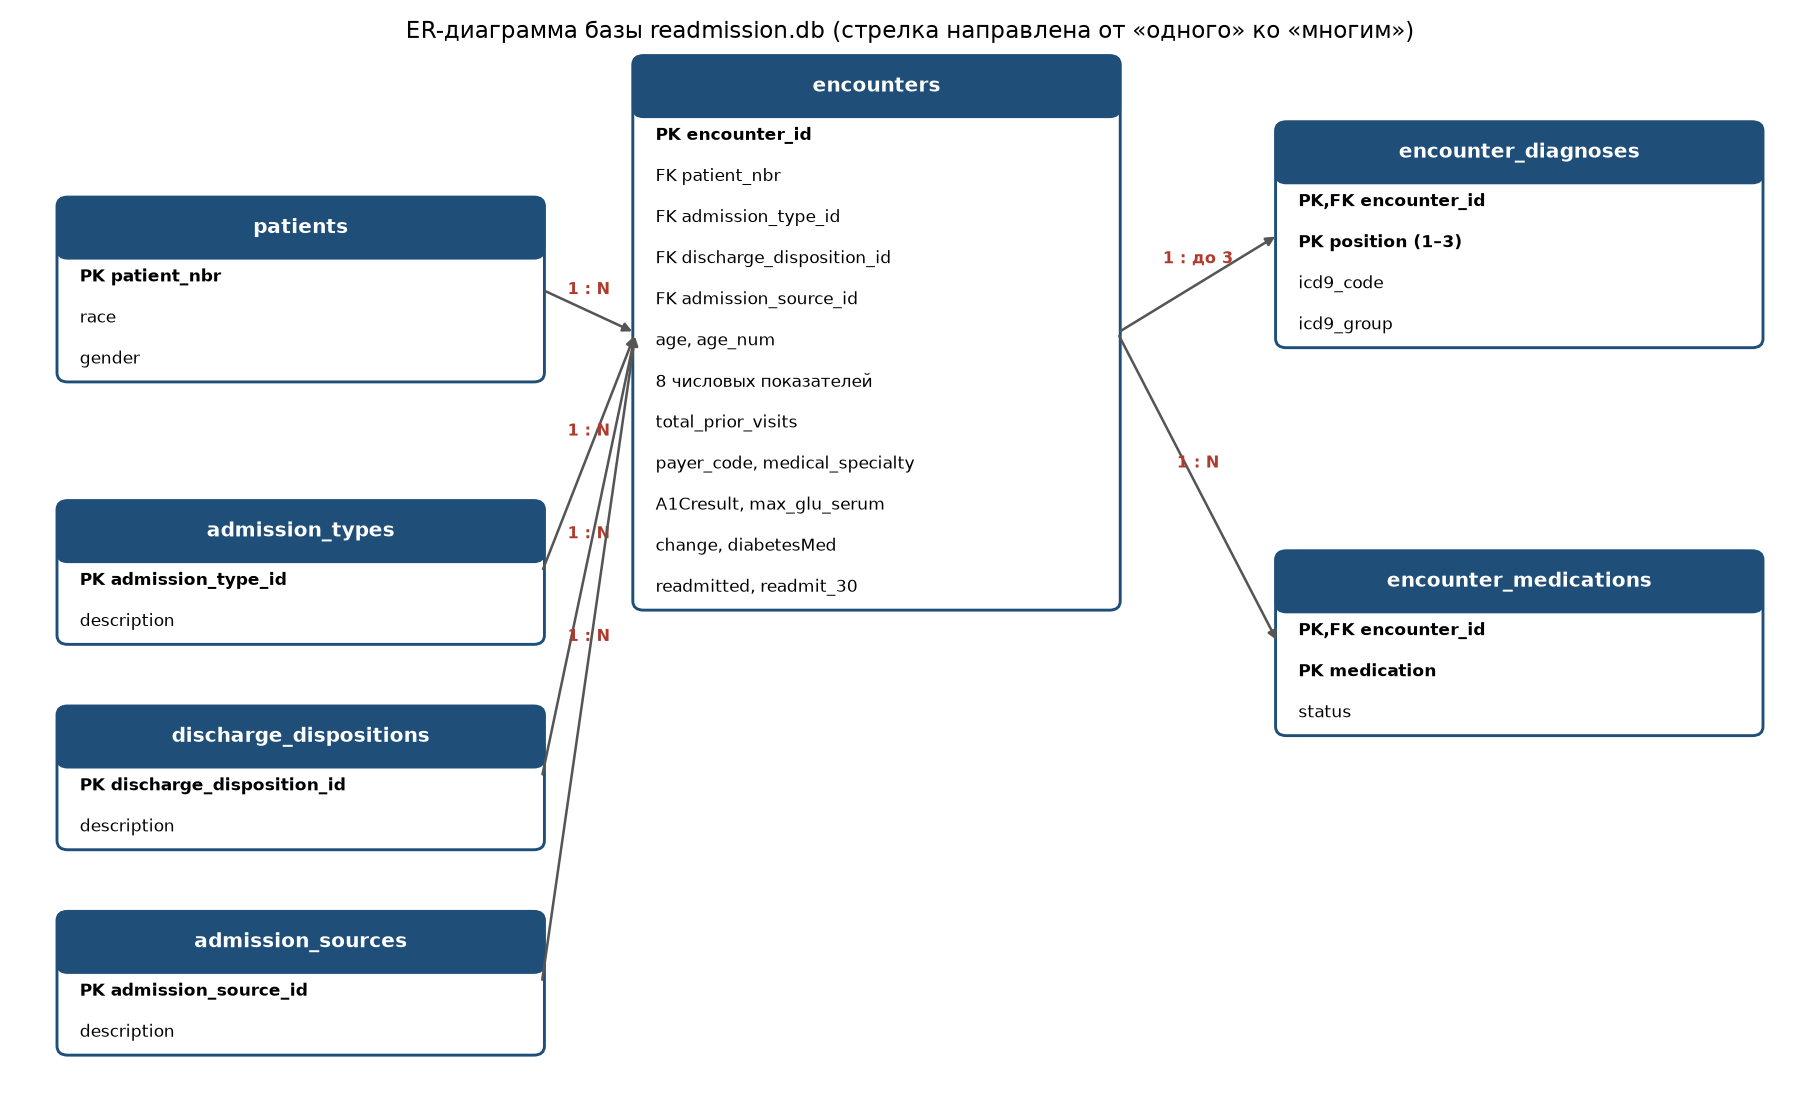

In [3]:
display(Image(filename=str(config.ROOT / 'docs' / 'er_diagram.png')))

## 4.3. Запросы

Все запросы читаются из файла функцией `load_queries`, выполняются через `run_query` и возвращаются как `DataFrame`. Столбец `readmit_pct` — процент визитов, после которых пациент вернулся раньше 30 дней.

In [4]:
queries = database.load_queries()
print('Запросов в файле:', len(queries))


def show(name):
    """Показать текст запроса и его результат."""
    display(Markdown('```sql\n' + queries[name].strip() + '\n```'))
    return database.run_query(queries[name])

Запросов в файле: 8


### Запрос 1. Возвраты по группе основного диагноза

**Приёмы SQL:** JOIN + GROUP BY

In [5]:
show('q1_by_diagnosis')

```sql
-- Основной диагноз учитываем один раз на визит, чтобы не завышать число госпитализаций.
SELECT d.icd9_group, COUNT(*) AS encounters,
       ROUND(AVG(e.readmit_30) * 100, 1) AS readmit_pct
FROM encounters AS e
JOIN encounter_diagnoses AS d ON d.encounter_id = e.encounter_id
WHERE d.position = 1
GROUP BY d.icd9_group
ORDER BY readmit_pct DESC, d.icd9_group;
```

,icd9_group,encounters,readmit_pct
0,Diabetes,8661,13.1
1,Injury,6851,12.4
2,Circulatory,29680,11.7
3,Other,17793,11.7
4,Genitourinary,5002,11.0
5,Neoplasms,3131,10.9
6,Digestive,9333,10.8
7,Respiratory,13934,10.1
8,Musculoskeletal,4935,9.5


**Вывод.** Чаще всего возвращаются пациенты, у которых основной диагноз — сам диабет (13.1%), реже всего — с болезнями костно-мышечной системы (9.5%). Разброс между группами небольшой.

### Запрос 2. Возвраты по возрасту

**Приёмы SQL:** GROUP BY

In [6]:
show('q2_by_age')

```sql
-- Возраст задан интервалами; сортируем по их нижней границе.
SELECT age, COUNT(*) AS encounters,
       ROUND(AVG(readmit_30) * 100, 1) AS readmit_pct
FROM encounters
GROUP BY age
ORDER BY CAST(SUBSTR(age, 2) AS INTEGER), age;
```

,age,encounters,readmit_pct
0,[0-10),160,1.9
1,[10-20),690,5.8
2,[20-30),1649,14.3
3,[30-40),3764,11.3
4,[40-50),9607,10.7
5,[50-60),17060,9.8
6,[60-70),22058,11.3
7,[70-80),25329,12.1
8,[80-90),16434,12.6
9,[90-100),2589,11.9


**Вывод.** У взрослых пациентов доля возвратов держится около 10–13% и слабо зависит от возраста.

### Запрос 3. Возвраты по числу прошлых госпитализаций

**Приёмы SQL:** GROUP BY + WHERE

In [7]:
show('q3_by_prior_visits')

```sql
-- Сравниваем возвраты по числу прошлых госпитализаций, оставляя значения до 10 включительно.
SELECT number_inpatient, COUNT(*) AS encounters,
       ROUND(AVG(readmit_30) * 100, 1) AS readmit_pct
FROM encounters
WHERE number_inpatient <= 10
GROUP BY number_inpatient
ORDER BY number_inpatient;
```

,number_inpatient,encounters,readmit_pct
0,0,66242,8.6
1,1,18984,13.3
2,2,7300,17.9
3,3,3271,21.0
4,4,1574,24.1
5,5,791,32.0
6,6,474,34.8
7,7,262,36.3
8,8,145,46.2
9,9,109,43.1


**Вывод.** Самая сильная зависимость: без госпитализаций за прошлый год возвращаются 8.6%, при восьми — 46.2%.

### Запрос 4. Возвраты по типу выписки

**Приёмы SQL:** JOIN со справочником + HAVING

In [8]:
show('q4_by_discharge')

```sql
-- Небольшие группы выписок исключаем, чтобы проценты не опирались на редкие случаи.
SELECT e.discharge_disposition_id, d.description, COUNT(*) AS encounters,
       ROUND(AVG(e.readmit_30) * 100, 1) AS readmit_pct
FROM encounters AS e
JOIN discharge_dispositions AS d
  ON d.discharge_disposition_id = e.discharge_disposition_id
GROUP BY e.discharge_disposition_id, d.description
HAVING COUNT(*) >= 500
ORDER BY readmit_pct DESC, e.discharge_disposition_id;
```

,discharge_disposition_id,description,encounters,readmit_pct
0,22,Discharged/transferred to another rehab fac including rehab units ...,1992,27.7
1,5,Discharged/transferred to another type of inpatient care institution,1184,20.9
2,2,Discharged/transferred to another short term hospital,2128,16.1
3,3,Discharged/transferred to SNF,13954,14.7
4,7,Left AMA,623,14.4
5,4,Discharged/transferred to ICF,815,12.8
6,6,Discharged/transferred to home with home health service,12902,12.7
7,18,Unknown,3691,12.4
8,1,Discharged to home,60232,9.3
9,25,Unknown,989,9.3


**Вывод.** Выписанные домой возвращаются реже всего (9.3%), переведённые в реабилитационное отделение — чаще всего (27.7%). `HAVING` отсекает типы выписки, где меньше 500 визитов.

### Запрос 5. Возвраты и инсулин

**Приёмы SQL:** LEFT JOIN + COALESCE

In [9]:
show('q5_by_insulin')

```sql
-- Условие по инсулину в JOIN сохраняет визиты без назначения: их нет в таблице лекарств.
SELECT COALESCE(m.status, 'Not prescribed') AS insulin_status,
       COUNT(*) AS encounters,
       ROUND(AVG(e.readmit_30) * 100, 1) AS readmit_pct
FROM encounters AS e
LEFT JOIN encounter_medications AS m
  ON m.encounter_id = e.encounter_id AND m.medication = 'insulin'
GROUP BY COALESCE(m.status, 'Not prescribed')
ORDER BY readmit_pct DESC, insulin_status;
```

,insulin_status,encounters,readmit_pct
0,Down,11908,14.2
1,Up,10987,13.3
2,Steady,30069,11.4
3,Not prescribed,46376,10.2


**Вывод.** В таблице лекарств хранятся только назначенные препараты, поэтому нужен `LEFT JOIN`: визиты без инсулина получают `NULL`, а `COALESCE` превращает его в «Not prescribed». Чаще возвращаются те, кому дозу меняли (13–14%), реже — те, кому инсулин не назначали (10.2%).

### Запрос 6. Отделения с долей возвратов выше средней

**Приёмы SQL:** HAVING + подзапрос

In [10]:
show('q6_specialties_above_average')

```sql
-- Сравниваем неокруглённые доли со средним по всем визитам; Unknown не считаем отделением.
SELECT medical_specialty, COUNT(*) AS encounters,
       ROUND(AVG(readmit_30) * 100, 1) AS readmit_pct
FROM encounters
WHERE medical_specialty <> 'Unknown'
GROUP BY medical_specialty
HAVING COUNT(*) >= 500
   AND AVG(readmit_30) > (SELECT AVG(readmit_30) FROM encounters)
ORDER BY readmit_pct DESC, medical_specialty;
```

,medical_specialty,encounters,readmit_pct
0,Nephrology,1539,16.1
1,Surgery-Vascular,525,14.1
2,Psychiatry,853,12.2
3,Family/GeneralPractice,7252,12.1
4,InternalMedicine,14237,11.5
5,Emergency/Trauma,7419,11.4


**Вывод.** Подзапрос считает среднюю долю возвратов по всем визитам, `HAVING` оставляет отделения выше неё. Лидер — нефрология (16.1%).

### Запрос 7. Пациенты с наибольшим числом визитов

**Приёмы SQL:** GROUP BY + ORDER BY + LIMIT

In [11]:
show('q7_top_patients')

```sql
-- При одинаковом числе визитов номер пациента задаёт воспроизводимый порядок.
SELECT patient_nbr, COUNT(*) AS encounters
FROM encounters
GROUP BY patient_nbr
ORDER BY encounters DESC, patient_nbr
LIMIT 10;
```

,patient_nbr,encounters
0,88785891,40
1,43140906,28
2,1660293,23
3,23199021,23
4,88227540,23
5,23643405,22
6,84428613,22
7,92709351,21
8,23398488,20
9,29903877,20


**Вывод.** У одного пациента 40 госпитализаций. Именно из-за таких пациентов данные для модели делятся на train и test по пациентам, а не по строкам.

### Запрос 8. Возвраты по номеру визита пациента

**Приёмы SQL:** CTE + оконная функция ROW_NUMBER

In [12]:
show('q8_visit_number')

```sql
-- Нумеруем доступные визиты пациента по encounter_id; пятый и последующие объединяем в 5+.
WITH numbered_visits AS (
    SELECT patient_nbr, encounter_id, readmit_30,
           ROW_NUMBER() OVER (
               PARTITION BY patient_nbr ORDER BY encounter_id
           ) AS visit_number
    FROM encounters
), visit_bands AS (
    SELECT CASE WHEN visit_number >= 5 THEN 5 ELSE visit_number END AS visit_number,
           readmit_30
    FROM numbered_visits
)
SELECT visit_number,
       CASE WHEN visit_number = 5 THEN '5+' ELSE CAST(visit_number AS TEXT) END AS visit_label,
       COUNT(*) AS encounters,
       ROUND(AVG(readmit_30) * 100, 1) AS readmit_pct
FROM visit_bands
GROUP BY visit_number
ORDER BY visit_number;
```

,visit_number,visit_label,encounters,readmit_pct
0,1,1,69987,9.0
1,2,2,16341,14.2
2,3,3,6123,17.4
3,4,4,2890,19.4
4,5,5+,3999,27.1


**Вывод.** `ROW_NUMBER() OVER (PARTITION BY patient_nbr ...)` нумерует визиты каждого пациента. После первого визита возвращаются 9.0%, после пятого и следующих — 27.1%: чем больше у человека госпитализаций, тем выше риск.

## Итог

| Что требуется | Где выполнено |
|---|---|
| Загрузка данных в SQLite | `prepare_database`, 7 таблиц с первичными и внешними ключами |
| ER-диаграмма | `docs/er_diagram.png` |
| JOIN | запросы 1, 4, 5 |
| GROUP BY / HAVING | все запросы / запросы 4 и 6 |
| Подзапрос | запрос 6 |
| CTE | запрос 8 |
| Оконная функция | запрос 8 |
| Результаты в Pandas | `run_query` возвращает `DataFrame` |

Выводы SQL-анализа совпадают с EDA (ноутбук 02): главный фактор риска — история госпитализаций пациента.